# 02 · Segmentação comportamental (PCA + K-means)

**Pergunta do notebook:** que tipos de cliente existem, olhando só **como eles usam e pagam o cartão**?

Esses grupos (segmentos) dão o contexto que atravessa o projeto: o dashboard, a política por faixa e a checagem de desempenho por grupo.

**Regras deste notebook**
- **Sem o alvo** para formar os grupos: a segmentação descreve comportamento, ela não prevê default. A taxa de default de cada grupo só é olhada **depois**, como descrição.
- **Sem perfil demográfico** (sexo, idade, escolaridade, estado civil): grupos devem refletir comportamento, não quem a pessoa é.
- **Só o treino** (24.000 clientes).

**Critérios fixados antes de rodar**

| Decisão | Critério |
|---|---|
| Nº de componentes do PCA | o menor que explique **≥ 80%** da variância |
| Nº de grupos (Parte B) | k entre 3 e 8, melhor silhueta, com todo grupo ≥ 5% dos clientes |
| Estabilidade (Parte B) | ARI ≥ 0,8 entre sementes diferentes |
| Grupo como variável do modelo (Parte B) | só se o PR AUC subir com win rate > 60% nos folds |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from xgboost import XGBClassifier

from credit_risk import config
from credit_risk.evaluate import cv_scores, paired_comparison
from credit_risk.features import behavior_features
from credit_risk.segmentation import (
    SegmentEncoder,
    choose_k,
    choose_n_components,
    explained_variance_table,
    kmeans_selection,
    loadings,
    make_pca_pipeline,
    segment_profile,
    stability,
)
from credit_risk.split import load_train
from credit_risk.stats import rate_by_group
from credit_risk.viz import (
    CATEGORICAL,
    CONTEXT,
    HIGHLIGHT,
    SURFACE,
    pct,
    plot_rate_by_group,
    save,
    set_style,
)

set_style()
pd.set_option("display.precision", 3)

df = load_train()
X = behavior_features(df)
X.shape

(24000, 17)

## 1. As features comportamentais

Para cada cliente, três comportamentos ao longo dos meses:

| Feature | O que mede | Regra fixa |
|---|---|---|
| `utilization_1..6` | quanto do limite a fatura ocupa (fatura ÷ limite) | fatura negativa → 0; limitado a 150% |
| `payment_ratio_1..5` | quanto da fatura anterior o cliente pagou | sem fatura a pagar → 1 (em dia); pagar a mais → 1 |
| `delay_1..6` | meses de atraso | status ≤ 0 → 0 |

O índice 1 é setembro (o mais recente). A taxa de pagamento tem só 5 meses porque o pagamento de abril quitaria a fatura de março, que não está nos dados.

São **regras fixas**, iguais para qualquer cliente, por isso não há vazamento de dados.

In [2]:
X.describe().T[["mean", "50%", "min", "max"]]

,mean,50%,min,max
utilization_1,0.421,0.315,0.0,1.5
utilization_2,0.409,0.296,0.0,1.5
utilization_3,0.390,0.272,0.0,1.5
utilization_4,0.358,0.242,0.0,1.5
utilization_5,0.332,0.211,0.0,1.5
utilization_6,0.317,0.182,0.0,1.5
payment_ratio_1,0.403,0.101,0.0,1.0
payment_ratio_2,0.412,0.104,0.0,1.0
payment_ratio_3,0.403,0.084,0.0,1.0
payment_ratio_4,0.404,0.078,0.0,1.0


## 2. Por que padronizar antes do PCA

O PCA procura as direções de **maior variação**. Se uma coluna varia de 0 a 8 (atraso) e outra de 0 a 1 (taxa de pagamento), o atraso "grita mais alto" só por causa da escala, e não por ser mais importante.

A **padronização** (*standardization*) põe todas as colunas na mesma régua: subtrai a média e divide pelo desvio-padrão. Exemplo: se a utilização média é 0,40 com desvio de 0,30, um cliente com 0,70 vira (0,70 − 0,40) ÷ 0,30 = **+1,0** ("um desvio acima da média").

A média e o desvio são **aprendidos dos dados**, por isso ficam dentro do pipeline: na validação cruzada, eles são recalculados só com o treino de cada fold.

In [3]:
spread = X.std().groupby(lambda c: c.rsplit("_", 1)[0]).mean()
spread.rename("desvio-padrão médio (antes de padronizar)").to_frame()

,desvio-padrão médio (antes de padronizar)
delay,0.753
payment_ratio,0.447
utilization,0.371


## 3. PCA: quantas "direções" resumem o comportamento?

O PCA (*análise de componentes principais*) troca as 17 colunas por novas colunas, os **componentes**, que são combinações das originais. O primeiro componente guarda a maior variação possível; o segundo, a maior variação que sobrou, sem repetir a informação do primeiro; e assim por diante.

**Álgebra linear por trás:** os componentes são os **autovetores** da matriz de covariância dos dados padronizados, e o **autovalor** de cada um diz quanta variância ele carrega. Como cada coluna padronizada tem variância 1, a soma dos autovalores é 17.

In [4]:
pipe = make_pca_pipeline().fit(df)
pca_full = pipe.named_steps["pca"]
variance = explained_variance_table(pca_full)
n_comp = choose_n_components(variance["acumulada"])
kaiser = int((variance["autovalor"] > 1).sum())
print(f"Soma dos autovalores: {variance['autovalor'].sum():.2f} (= nº de colunas)")
print(f"Componentes para >= 80%: {n_comp}  |  Regra de Kaiser (autovalor > 1): {kaiser}")
variance.head(8)

Soma dos autovalores: 17.00 (= nº de colunas)
Componentes para >= 80%: 4  |  Regra de Kaiser (autovalor > 1): 3


,variancia,acumulada,autovalor
PC1,0.507,0.507,8.614
PC2,0.195,0.702,3.320
PC3,0.067,0.769,1.137
PC4,0.054,0.823,0.921
PC5,0.035,0.858,0.601
PC6,0.029,0.887,0.494
PC7,0.022,0.909,0.373
PC8,0.017,0.927,0.295


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/seg_01_variancia_pca.png')

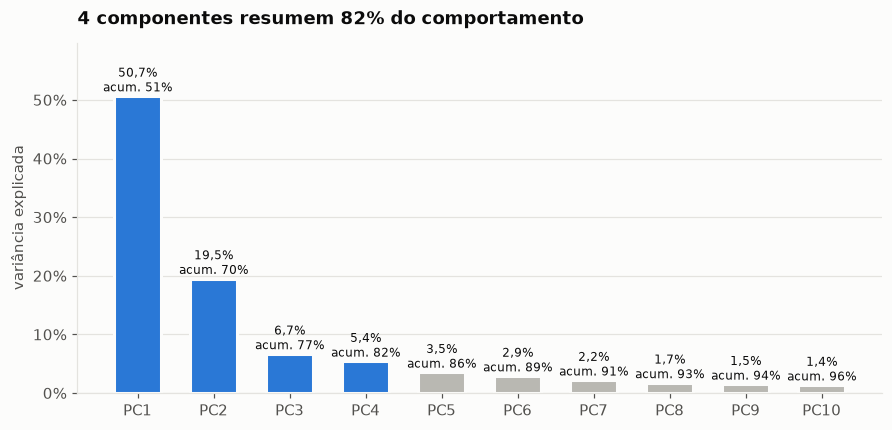

In [5]:
top = variance.head(10)
fig, ax = plt.subplots(figsize=(8, 3.8))
colors = [HIGHLIGHT if i < n_comp else CONTEXT for i in range(len(top))]
ax.bar(top.index, top["variancia"], color=colors, width=0.62, edgecolor=SURFACE, linewidth=2)
for i, (v, acc) in enumerate(zip(top["variancia"], top["acumulada"], strict=True)):
    ax.annotate(
        f"{pct(v)}\nacum. {pct(acc, 0)}",
        (i, v),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        fontsize=8,
    )
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pct(v, 0)))
ax.set_ylabel("variância explicada")
ax.margins(y=0.18)
kept = pct(top["acumulada"].iloc[n_comp - 1], 0)
ax.set_title(f"{n_comp} componentes resumem {kept} do comportamento")
save(fig, "seg_01_variancia_pca")

**Evidência:** o 1º componente sozinho explica **50,7%** da variação; os 4 primeiros, **82,3%**. A regra de Kaiser indicaria 3 (o 4º tem autovalor 0,92, um pouco abaixo de 1).

**Decisão:** fico com **4 componentes**, como fixado antes de rodar. Trocar 17 colunas por 4 perde menos de 18% da informação e deixa o K-means mais estável.

## 4. O que cada componente significa

As **cargas** (*loadings*) dizem quanto cada coluna original pesa em cada componente. Carga positiva: quando a coluna sobe, o componente sobe. Carga negativa: o contrário. Carga perto de zero: a coluna quase não participa.

,PC1,PC2,PC3,PC4
utilization_1,0.28,-0.16,0.23,0.00
utilization_2,0.30,-0.15,0.23,-0.02
utilization_3,0.30,-0.14,0.23,-0.08
utilization_4,0.30,-0.11,0.23,-0.16
utilization_5,0.30,-0.08,0.22,-0.22
utilization_6,0.29,-0.07,0.21,-0.23
payment_ratio_1,-0.28,0.06,0.24,-0.27
payment_ratio_2,-0.29,0.06,0.29,-0.22
payment_ratio_3,-0.28,0.06,0.34,-0.15
payment_ratio_4,-0.27,0.05,0.35,-0.09


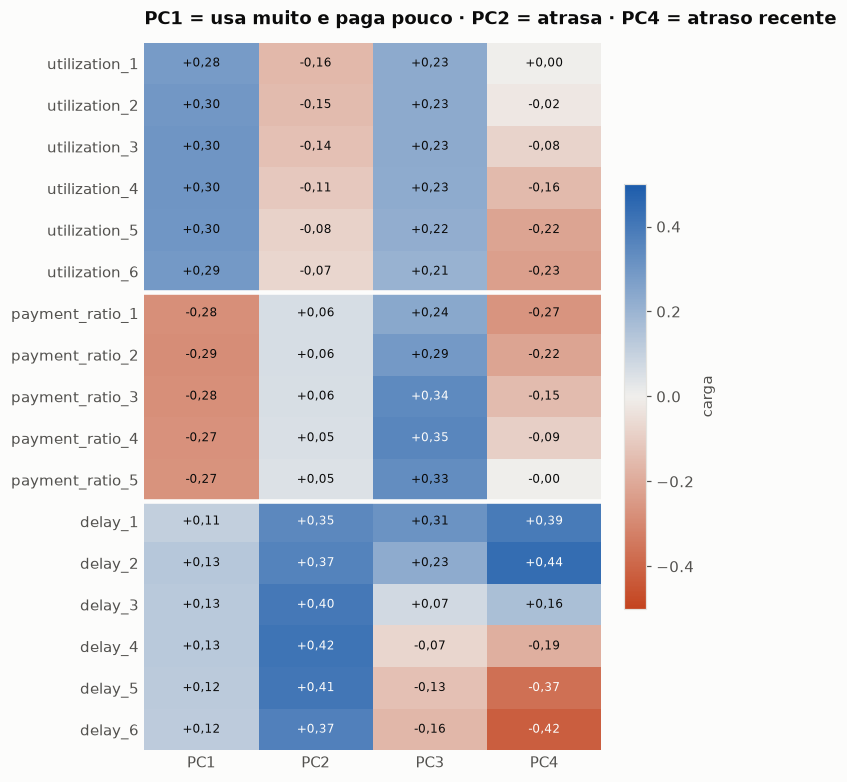

In [6]:
pca = make_pca_pipeline(n_comp).fit(df).named_steps["pca"]
load = loadings(pca, config.BEHAVIOR_FEATURES)

diverging = LinearSegmentedColormap.from_list("div", ["#c4441f", "#f0efec", "#1c5cab"])
fig, ax = plt.subplots(figsize=(6.5, 7))
im = ax.imshow(load.to_numpy(), cmap=diverging, vmin=-0.5, vmax=0.5, aspect="auto")
for (i, j), v in np.ndenumerate(load.to_numpy()):
    ax.text(
        j,
        i,
        f"{v:+.2f}".replace(".", ","),
        ha="center",
        va="center",
        fontsize=8,
        color=SURFACE if abs(v) > 0.33 else "#0b0b0b",
    )
ax.set_xticks(range(n_comp), load.columns)
ax.set_yticks(range(len(load)), load.index)
for y in (5.5, 10.5):
    ax.axhline(y, color=SURFACE, linewidth=3)
ax.grid(False)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.6, label="carga")
ax.set_title("PC1 = usa muito e paga pouco · PC2 = atrasa · PC4 = atraso recente")
save(fig, "seg_02_cargas_pca")
load.round(2)

**Leitura das cargas:**

| Componente | Variância | Cargas fortes | Nome de negócio |
|---|---|---|---|
| **PC1** | 50,7% | utilização **+** (≈ 0,30) e taxa de pagamento **−** (≈ −0,28) em todos os meses | **"rotativo"**: usa muito do limite e paga pouco da fatura. No polo oposto, quem usa pouco e quita tudo |
| **PC2** | 19,5% | atraso **+** em todos os meses (0,35 a 0,42) | **"atraso"**: quanto o cliente atrasa, de forma geral |
| **PC3** | 6,7% | utilização **+** e taxa de pagamento **+** juntas; atraso recente + e antigo − | **"usa muito, mas paga"**: grande utilização sem rotativo. Leitura menos limpa que as anteriores |
| **PC4** | 5,4% | atraso **recente +** (set/ago: 0,39 e 0,44) e **antigo −** (mai/abr: −0,37 e −0,42) | **"tendência do atraso"**: positivo = **piorando** (o atraso começou agora); negativo = melhorando |

A EDA já tinha mostrado que o atraso recente vale mais que o antigo. O PC4 isola exatamente essa diferença, e ele **não depende do alvo**: o PCA chegou lá só olhando o comportamento.

**Os sinais de um componente são arbitrários:** o PCA poderia ter devolvido o PC1 com todas as cargas invertidas, e a leitura seria a mesma ("paga muito e usa pouco"). O que importa é o contraste entre as colunas.

## 5. Os clientes no mapa dos dois primeiros componentes

Cada ponto é um cliente, posicionado pelos seus valores em PC1 (rotativo) e PC2 (atraso). As áreas mais escuras concentram mais clientes.

PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/seg_03_mapa_pca.png')

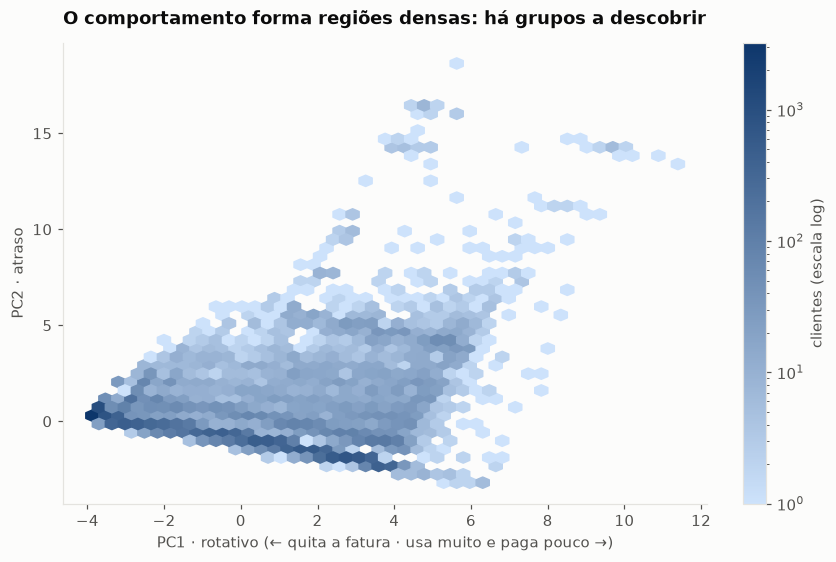

In [7]:
scores = pd.DataFrame(make_pca_pipeline(n_comp).fit_transform(df), columns=load.columns)
fig, ax = plt.subplots(figsize=(7.5, 5))
hb = ax.hexbin(
    scores["PC1"],
    scores["PC2"],
    gridsize=45,
    bins="log",
    mincnt=1,
    cmap=LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#0d366b"]),
)
ax.grid(False)
fig.colorbar(hb, ax=ax, label="clientes (escala log)")
ax.set_xlabel("PC1 · rotativo (← quita a fatura · usa muito e paga pouco →)")
ax.set_ylabel("PC2 · atraso")
ax.set_title("O comportamento forma regiões densas: há grupos a descobrir")
save(fig, "seg_03_mapa_pca")

**Evidência:** os clientes não se espalham de forma uniforme. Há uma grande massa com pouco atraso, que vai de "quita tudo" (esquerda) a "rotativo" (direita), e "braços" que sobem na direção do atraso.

**Decisão:** seguir para o K-means (Parte B) usando os **4 componentes**, para encontrar e nomear esses grupos.

# Parte B · K-means: quais grupos existem?

**A ideia:** imagine espalhar alfinetes num mapa e pedir "coloque k bandeiras de forma que cada alfinete fique o mais perto possível da sua bandeira". O **K-means** escolhe k centros e atribui cada cliente ao centro mais próximo, repetindo até estabilizar. Aqui, o "mapa" são os 4 componentes do PCA.

Para escolher k, uso duas medidas:
- **Inércia** (soma das distâncias ao quadrado até o centro do grupo): sempre cai com mais grupos. O **cotovelo** é o ponto em que ela passa a cair pouco.
- **Silhueta** (de -1 a 1): para cada cliente, compara a distância até o próprio grupo com a distância até o grupo vizinho. Perto de 1 = grupo bem separado.

**Critério fixado:** k entre 3 e 8, melhor silhueta, desde que **todo grupo tenha ≥ 5% dos clientes**. Um grupo minúsculo não vira política.

In [8]:
encoder_pca = make_pca_pipeline(config.PCA_N_COMPONENTS).fit(df)
pc_scores = encoder_pca.transform(df)
selection = kmeans_selection(pc_scores)
k_best = choose_k(selection)
selection.to_csv(config.REPORTS_DIR / "segment_k_selection.csv", index=False)
print(f"k escolhido: {k_best}")
selection

k escolhido: 3


,k,inercia,silhueta,menor_grupo
0,3,114574.956,0.519,0.097
1,4,83830.373,0.481,0.090
2,5,73046.703,0.484,0.066
3,6,64952.222,0.490,0.005
4,7,58268.775,0.438,0.005
5,8,52514.834,0.445,0.005


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/seg_04_escolha_k.png')

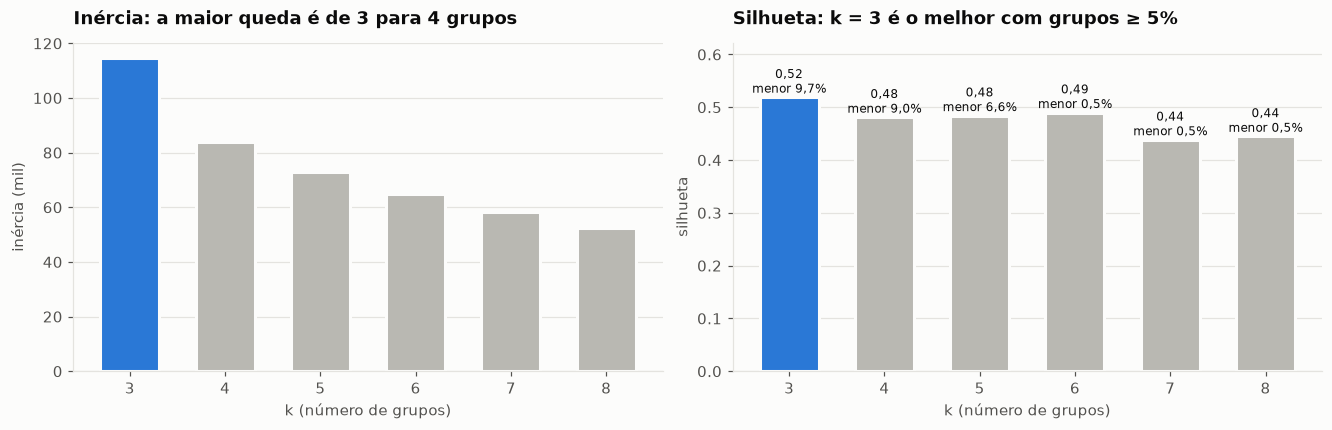

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
colors = [HIGHLIGHT if k == k_best else CONTEXT for k in selection["k"]]
axes[0].bar(
    selection["k"],
    selection["inercia"] / 1e3,
    color=colors,
    width=0.62,
    edgecolor=SURFACE,
    linewidth=2,
)
axes[0].set_xlabel("k (número de grupos)")
axes[0].set_ylabel("inércia (mil)")
axes[0].set_title("Inércia: a maior queda é de 3 para 4 grupos")
axes[1].bar(
    selection["k"], selection["silhueta"], color=colors, width=0.62, edgecolor=SURFACE, linewidth=2
)
for k, s, m in selection[["k", "silhueta", "menor_grupo"]].itertuples(index=False):
    tag = f"{s:.2f}".replace(".", ",") + f"\nmenor {pct(m)}"
    axes[1].annotate(
        tag, (k, s), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8
    )
axes[1].margins(y=0.2)
axes[1].set_xlabel("k (número de grupos)")
axes[1].set_ylabel("silhueta")
axes[1].set_title(f"Silhueta: k = {k_best} é o melhor com grupos ≥ 5%")
save(fig, "seg_04_escolha_k")

**Evidência:**
- A **silhueta** é máxima com **k = 3** (0,52). O cotovelo da inércia apontaria para 4.
- A partir de **k = 6** aparece um grupo com só **0,5%** dos clientes: é a cauda de atraso extremo vista no mapa, que o K-means isola num grupo próprio (o K-means é sensível a pontos extremos). A regra do tamanho mínimo descarta essas opções.

**Decisão:** **k = 3**, pelo critério fixado (silhueta). O cotovelo fica registrado como uma opinião divergente.

### Os grupos são estáveis?

Um agrupamento só serve se ele **se repete**. Meço com o **ARI** (*Adjusted Rand Index*): uma nota de 0 a 1 de quão iguais são duas divisões dos mesmos clientes (1 = idênticas, 0 = iguais a um sorteio). Testo (a) 5 sementes diferentes e (b) 10 ajustes em subamostras com 80% dos clientes. Critério: ARI ≥ 0,8.

In [10]:
stab = stability(pc_scores, k_best)
pd.Series(stab).round(4).to_frame("ARI")

,ARI
ari_min_sementes,0.999
ari_min_subamostras,0.994
ari_medio_subamostras,0.997


**Evidência:** ARI ≥ 0,99 nos dois testes, bem acima do critério de 0,8. Os três grupos não são um acaso da semente nem dos clientes sorteados.

## 6. Perfil e nome de cada grupo

Os rótulos do K-means (0, 1, 2) são arbitrários e podem mudar entre execuções. Por isso o `SegmentEncoder` **renomeia por regra**: o grupo com mais meses em atraso recebe o último código, e os demais são ordenados pela utilização. Assim, os códigos e os nomes ficam estáveis.

In [11]:
encoder = SegmentEncoder().fit(df)
segments = encoder.predict(df)
profile = segment_profile(df, segments)
profile.to_csv(config.REPORTS_DIR / "segment_profiles.csv")
profile

,nome,clientes,participacao,utilizacao_set,utilizacao_abr,paga_da_fatura,quita_todo_mes,meses_com_atraso,limite_mediano
segment,,,,,,,,,
0,quitadores,10345,0.431,0.086,0.045,0.825,0.52,0.359,200000.0
1,rotativo em dia,11330,0.472,0.688,0.503,0.103,0.00,0.442,100000.0
2,atraso crônico,2325,0.097,0.610,0.624,0.065,0.00,4.874,60000.0


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/seg_05_perfil_segmentos.png')

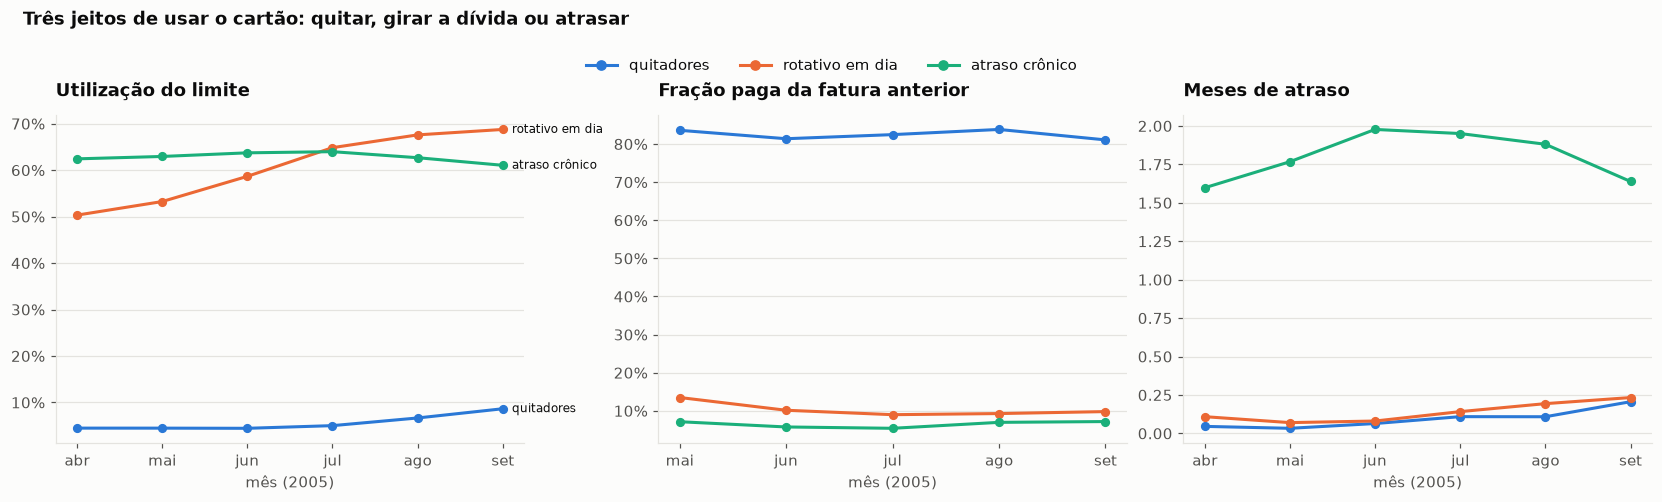

In [12]:
b = behavior_features(df)
months = ["set", "ago", "jul", "jun", "mai", "abr"]
series = {
    "Utilização do limite": (config.UTILIZATION, months),
    "Fração paga da fatura anterior": (config.PAYMENT_RATIO, months[:5]),
    "Meses de atraso": (config.DELAY, months),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (title, (cols, labels)) in zip(axes, series.items(), strict=True):
    means = b[cols].groupby(segments).mean()
    for seg, color in zip(means.index, CATEGORICAL, strict=True):
        y_vals = means.loc[seg].to_numpy()[::-1]
        ax.plot(labels[::-1], y_vals, color=color, linewidth=2, marker="o", markersize=5)
        if ax is axes[0]:
            ax.annotate(
                config.SEGMENT_NAMES[seg],
                (len(labels) - 1, y_vals[-1]),
                xytext=(6, 0),
                textcoords="offset points",
                va="center",
                fontsize=8,
                color="#0b0b0b",
                annotation_clip=False,
            )
    ax.set_title(title)
    ax.set_xlabel("mês (2005)")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pct(v, 0)))
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pct(v, 0)))
handles = [plt.Line2D([], [], color=c, linewidth=2, marker="o") for c in CATEGORICAL]
fig.legend(
    handles, config.SEGMENT_NAMES.values(), loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.08)
)
fig.suptitle(
    "Três jeitos de usar o cartão: quitar, girar a dívida ou atrasar",
    x=0.01,
    ha="left",
    fontweight="bold",
    y=1.16,
)
save(fig, "seg_05_perfil_segmentos")

| Código | Nome | Como se comporta |
|---|---|---|
| 0 | **Quitadores** | usam pouco do limite (cerca de 9% em setembro), pagam a maior parte da fatura (metade deles quita **todo mês**), quase não atrasam e têm o **maior limite** (mediana de NT$ 200 mil) |
| 1 | **Rotativo em dia** | usam muito do limite (cerca de 69% em setembro, **subindo** desde abril), pagam só uma pequena parte da fatura (vivem no rotativo), mas **não atrasam** |
| 2 | **Atraso crônico** | usam bastante do limite, pagam muito pouco e atrasam em **quase 5 dos 6 meses**. Grupo pequeno (cerca de 10%), com o **menor limite** |

Os números exatos estão na tabela de perfil acima e em `reports/segment_profiles.csv`.

PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/seg_06_mapa_segmentos.png')

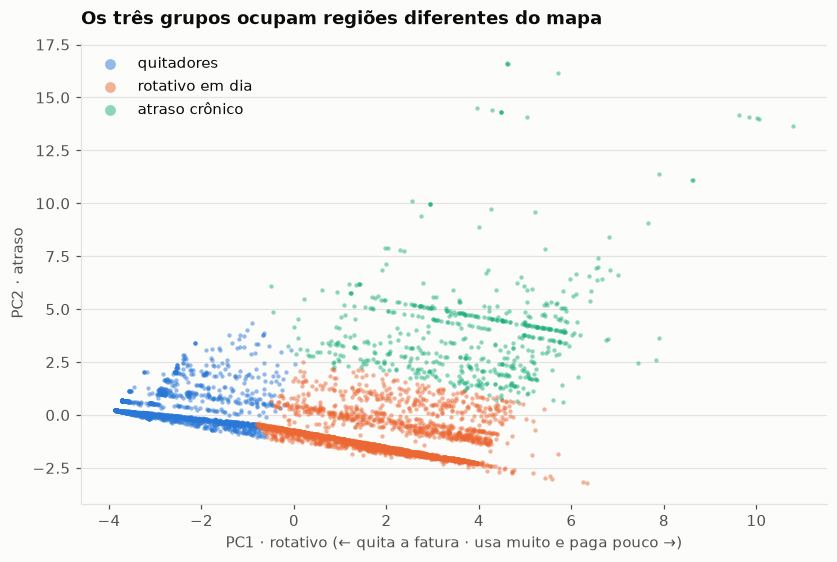

In [13]:
sample = np.random.default_rng(config.SEED).choice(len(pc_scores), 6_000, replace=False)
fig, ax = plt.subplots(figsize=(7.5, 5))
for seg, color in zip(range(k_best), CATEGORICAL, strict=True):
    m = segments[sample] == seg
    ax.scatter(
        pc_scores[sample][m, 0],
        pc_scores[sample][m, 1],
        s=8,
        color=color,
        alpha=0.5,
        linewidths=0,
        label=config.SEGMENT_NAMES[seg],
    )
ax.legend(markerscale=2.5, loc="upper left")
ax.set_xlabel("PC1 · rotativo (← quita a fatura · usa muito e paga pouco →)")
ax.set_ylabel("PC2 · atraso")
ax.set_title("Os três grupos ocupam regiões diferentes do mapa")
save(fig, "seg_06_mapa_segmentos")

## 7. Quanto cada grupo dá de default (descritivo)

Só agora, **depois** de formar os grupos, olho o alvo. Isso é descrição, não previsão: os grupos foram formados sem saber quem deu default.

,segment,n,defaults,taxa,ic_inf,ic_sup,nome
0,0,10345,1732,0.167,0.160,0.175,quitadores
1,1,11330,2127,0.188,0.181,0.195,rotativo em dia
2,2,2325,1450,0.624,0.604,0.643,atraso crônico


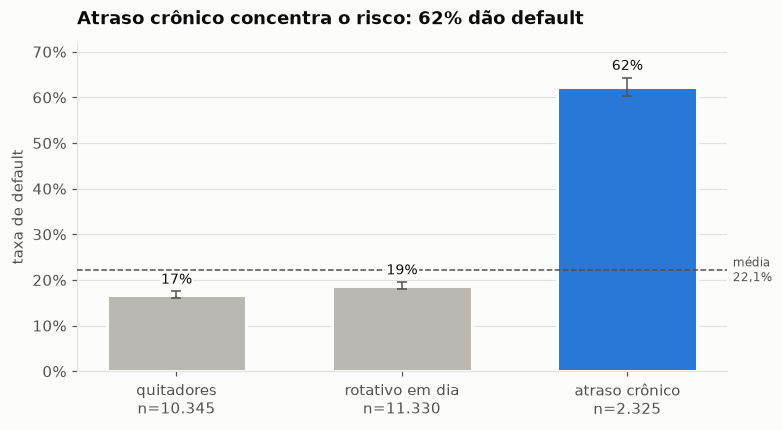

In [14]:
seg_rates = rate_by_group(df.assign(segment=segments), "segment")
fig, ax = plt.subplots(figsize=(7, 3.8))
plot_rate_by_group(
    seg_rates,
    "segment",
    "Atraso crônico concentra o risco: 62% dão default",
    df[config.TARGET].mean(),
    highlight=[2],
    labels=config.SEGMENT_NAMES,
    ax=ax,
)
save(fig, "seg_07_default_segmentos")
seg_rates.assign(nome=seg_rates["segment"].map(config.SEGMENT_NAMES)).round(4)

**Evidência:**
- **Atraso crônico:** cerca de **62%** de default, quase 3 vezes a média. São 10% dos clientes e respondem por mais de um quarto dos defaults.
- **Quitadores** (≈ 17%) e **rotativo em dia** (≈ 19%) ficam **perto um do outro**.

**Resultado que contraria a intuição:** viver no rotativo (usar 69% do limite e pagar pouco) quase não aumenta o risco **enquanto não há atraso**. O que separa o risco é o **atraso**, e não o uso do crédito. Isso conversa com a EDA: o histórico de pagamento é o sinal mais forte; o valor da fatura sozinho, não.

**Para o negócio:** o grupo "rotativo em dia" é o mais **rentável** para um emissor (paga juros) e tem risco parecido com o dos quitadores. Uma política que tratasse "rotativo" como risco cortaria receita sem reduzir perda.

## 8. Experimento: o segmento ajuda o modelo a prever?

**Hipótese:** o segmento resume o comportamento e pode ajudar um modelo, principalmente um modelo **linear** como a regressão logística, que sozinho não cria interações.

**Desenho:**
- Comparo um modelo com as informações de onde o segmento nasce (**limite + 17 features comportamentais**) contra o **mesmo modelo com o segmento junto** (em colunas 0/1).
- Dois modelos: regressão logística e XGBoost.
- Validação cruzada **5 folds × 3 repetições** (15 rodadas), com os **mesmos folds** para as duas variantes. Padronização, PCA e K-means são **reajustados dentro de cada fold** (sem vazamento).

**Critério fixado antes:** adoto o segmento como variável **só se** o PR AUC subir com **win rate > 60%** (o candidato vence em mais de 60% dos folds).

O PR AUC (*área sob a curva de precisão × recall*) mede o quanto o modelo consegue achar os inadimplentes sem acusar bons pagadores. Um modelo que chuta tem PR AUC igual à taxa de default (0,22).

In [15]:
def base_features(data: pd.DataFrame) -> pd.DataFrame:
    return pd.concat([data[["limit_bal"]], behavior_features(data)], axis=1)


def build(model, with_segment: bool) -> Pipeline:
    parts = [
        (
            "base",
            Pipeline([("feat", FunctionTransformer(base_features)), ("scale", StandardScaler())]),
        )
    ]
    if with_segment:
        parts.append(("segment", SegmentEncoder(one_hot=True)))
    return Pipeline([("features", FeatureUnion(parts)), ("model", model)])


models = {
    "logística": LogisticRegression(max_iter=2_000),
    "xgboost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=config.SEED,
        n_jobs=1,
    ),
}
X_all, y_all = df.drop(columns=[config.TARGET]), df[config.TARGET]
rows = []
for name, model in models.items():
    without = cv_scores(build(model, False), X_all, y_all)
    with_seg = cv_scores(build(model, True), X_all, y_all)
    for metric in ["pr_auc", "roc_auc", "brier"]:
        rows.append(
            {"modelo": name, "métrica": metric, **paired_comparison(without, with_seg, metric)}
        )
experiment = pd.DataFrame(rows)
experiment["adotar"] = (
    (experiment["métrica"] == "pr_auc")
    & (experiment["ganho_medio"] > 0)
    & (experiment["win_rate"] > config.WIN_RATE_MIN)
)
experiment.to_csv(config.REPORTS_DIR / "segment_experiment.csv", index=False)
experiment.round(4)

,modelo,métrica,base,candidato,ganho_medio,desvio_ganho,win_rate,adotar
0,logística,pr_auc,0.525,0.525,-3.000e-04,4.000e-04,0.267,False
1,logística,roc_auc,0.758,0.758,-1.000e-04,5.000e-04,0.467,False
2,logística,brier,0.139,0.139,-0.000e+00,0.000e+00,0.200,False
3,xgboost,pr_auc,0.555,0.555,1.000e-04,3.500e-03,0.467,False
4,xgboost,roc_auc,0.784,0.784,2.000e-04,1.300e-03,0.533,False
5,xgboost,brier,0.135,0.135,1.000e-04,3.000e-04,0.667,False


**Evidência:** o segmento **não melhora** nenhum dos dois modelos. Na logística, o PR AUC cai 0,0003 (win rate de 27%); no XGBoost, o ganho médio é de 0,0001, muito menor que a variação entre folds, e o win rate é de 47%. ROC AUC e Brier contam a mesma história.

**Por quê:** o segmento é um resumo de 3 categorias feito **a partir das mesmas 18 informações** que o modelo já recebe. Ele não traz dado novo, só uma versão mais grosseira do que já está lá.

**Decisão (pelo critério fixado): o segmento NÃO entra no modelo.** Resultado negativo também é resultado: ele evita adicionar complexidade (um K-means dentro do pipeline de produção) sem ganho. O segmento fica com o papel em que é bom: **explicar a carteira** no dashboard, na política por faixa e na análise de desempenho por grupo (Etapa 13).

## 9. Conclusões da segmentação

| # | Achado | Decisão |
|---|---|---|
| 1 | 4 componentes do PCA resumem **82,3%** do comportamento: rotativo, atraso, "usa e paga" e tendência do atraso | o agrupamento usa os 4 componentes |
| 2 | **k = 3** pela silhueta (0,52), com todos os grupos ≥ 5%; o cotovelo indicaria 4 | 3 segmentos |
| 3 | Grupos **muito estáveis** (ARI ≥ 0,99 entre sementes e subamostras) | segmentos confiáveis para uso em relatório |
| 4 | **Quitadores** (43%), **rotativo em dia** (47%) e **atraso crônico** (10%) | nomes de negócio usados em todo o projeto |
| 5 | Atraso crônico: **≈ 62%** de default; rotativo em dia ≈ quitadores (≈ 19% × 17%) | o risco vem do atraso, não do uso do rotativo |
| 6 | O segmento **não melhora** o modelo (win rate 27% e 47%) | fica fora do modelo; serve para interpretação |